2025-07-18 10:43:20.439357: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1752835400.461630 2499444 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1752835400.468717 2499444 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1752835400.486951 2499444 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1752835400.486973 2499444 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1752835400.486975 2499444 computation_placer.cc:177] computation placer alr

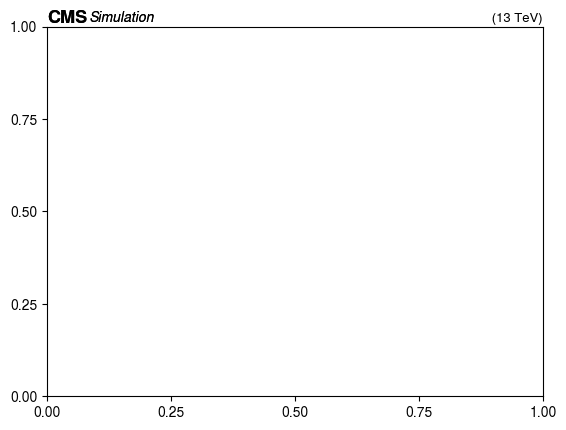

In [1]:
#imports
# deel LIP model components
from deel.lip.model import Model 
from deel.lip.layers import SpectralConv2D, SpectralDense, ScaledGlobalAveragePooling2D
from deel.lip.activations import GroupSort2
from deel.lip.losses import TauCategoricalCrossentropy
from deel.lip.normalizers import set_stop_grad_spectral
from deel.lip.metrics import CategoricalProvableAvgRobustness
# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import BatchNormalization, Input, Softmax
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model

import os
import shutil
import json
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
import mplhep as hep
import numpy as np
import tagger.plot.style as style  
from tagger.plot.common import PT_BINS
from sklearn.metrics import roc_curve, auc
from collections.abc import MutableMapping
import collections
collections.MutableMapping = MutableMapping  
import histbook
import pandas 
import awkward as ak

In [2]:
#functions for plotting ROC curves (slighlty modified)

def ROC(y_pred, y_test, class_labels, plot_dir,ROC_dict):
    # Create a colormap for unique colors
    colormap = cm.get_cmap('Set1', len(class_labels))  # Use 'tab10' with enough colors

    # Create a plot for ROC curves
    fig,ax = plt.subplots(1,1,figsize=style.FIGURE_SIZE)
    hep.cms.label(llabel=style.CMSHEADER_LEFT,rlabel=style.CMSHEADER_RIGHT,ax=ax, fontsize=style.CMSHEADER_SIZE)
    for i, class_label in enumerate(class_labels):

        # Get true labels and predicted probabilities for the current class
        y_true = y_test[:, i]  # Extract the one-hot column for the current class
        y_score = y_pred[:, i] # Predicted probabilities for the current class

        # Compute FPR, TPR, and AUC
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        ROC_dict[class_label] = roc_auc
        # Plot the ROC curve for the current class
        ax.plot(tpr, fpr, label=f'{style.CLASS_LABEL_STYLE[class_label]} (AUC = {roc_auc:.2f})',
                 color=colormap(i), linewidth=style.LINEWIDTH)

    # Plot formatting
    ax.grid(True)
    ax.set_ylabel('Mistag Rate')
    ax.set_xlabel('Signal Efficiency')

    auc_list = [value for key,value in ROC_dict.items()]
    handles, labels = plt.gca().get_legend_handles_labels()
    order = np.argsort(auc_list)
    ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order],loc='upper left',ncol=2,fontsize=style.SMALL_SIZE-3)

    ax.set_yscale('log')
    ax.set_ylim([1e-3, 1.1])

    # Save the plot
    save_path = os.path.join(plot_dir, "basic_ROC")
    plt.savefig(f"{save_path}.pdf", bbox_inches='tight')
    plt.savefig(f"{save_path}.png", bbox_inches='tight')
    plt.close()

    return ROC_dict

def efficiency(y_pred, y_test, reco_pt_test, class_labels, plot_dir):

    save_dir = os.path.join(plot_dir, 'efficiencies')
    os.makedirs(save_dir, exist_ok=True)

    # pT coordinate points for plotting
    pt_points = [np.mean((PT_BINS[i], PT_BINS[i + 1])) for i in range(len(PT_BINS) - 1)]

    def plot_efficiency(df_wp_loose, df_wp_medium, df_wp_tight, plot_name):
        # Plot the efficiency
        fig = plt.figure(figsize=style.FIGURE_SIZE)

        ax = df_wp_loose.plot.line(x="midpoints", y="wp_loose", yerr="err(wp_loose)", label = "Loose (mistag = 50%)", color="blue", linestyle='-')
        df_wp_medium.plot.line(x="midpoints", y="wp_medium", yerr="err(wp_medium)", label = "Medium (eff = 20%)", ax = ax, color="orange", linestyle='-')
        df_wp_tight.plot.line(x="midpoints", y="wp_tight", yerr="err(wp_tight)", label = "Tight (eff = 10%)", ax = ax, color="green", linestyle='-')
        plt.xlabel(r'Jet $p_T$ [GeV]')
        plt.ylabel('Tagging efficiency')
        plt.ylim(0., 1.3)
        #plt.xlim(0., 1000.)
        plt.legend()

        hep.cms.label(llabel=style.CMSHEADER_LEFT,rlabel=style.CMSHEADER_RIGHT,ax=ax,fontsize=style.CMSHEADER_SIZE)
        
        # Save the plot
        save_path = os.path.join(save_dir, plot_name)
        plt.savefig(f"{save_path}.pdf", bbox_inches='tight')
        plt.savefig(f"{save_path}.png", bbox_inches='tight')
        plt.cla()
        plt.close()

    eff_selection = {
        'taum': [ class_labels['taum']],
        'taup':[class_labels['taup']],
        'charm':[class_labels['charm']],
        'light':[class_labels['light']],
        'gluon': [class_labels['gluon']],
        'b': [class_labels['b']],
        'electron':[class_labels['electron']],
        'muon':[class_labels['muon']]
    }

    for key in eff_selection.keys():
        selection = sum(y_test[:, idx] for idx in eff_selection[key]) > 0
        summed_y_true = sum(y_test[:, idx] for idx in eff_selection[key])
        summed_y_score = sum(y_pred[:, idx] for idx in eff_selection[key])

        # Compute FPR, TPR, and AUC
        fpr, tpr, thres = roc_curve(summed_y_true, summed_y_score)
        roc_auc = auc(fpr, tpr)

        # get working points for 50%, 20%, 10%
        wp_loose = thres[np.argmin(np.abs(np.array(fpr)-0.5))]
        wp_medium = thres[np.argmin(np.abs(np.array(fpr)-0.2))]
        wp_tight = thres[np.argmin(np.abs(np.array(fpr)-0.1))]

        # some tricks to get proper uncertainties in the efficiencies
        data_eff = ak.to_dataframe(ak.Array({"truth": summed_y_true[selection], "pt": reco_pt_test[selection], "pred": summed_y_score[selection]}))
        data_eff["wp_loose"] = data_eff["pred"] > wp_loose
        data_eff["wp_medium"] = data_eff["pred"] > wp_medium
        data_eff["wp_tight"] = data_eff["pred"] > wp_tight

        h_wp_loose = histbook.Hist(histbook.split("pt", pt_points), histbook.cut("wp_loose"))
        h_wp_medium = histbook.Hist(histbook.split("pt", pt_points), histbook.cut("wp_medium"))
        h_wp_tight = histbook.Hist(histbook.split("pt", pt_points), histbook.cut("wp_tight"))
        h_wp_loose.fill(data_eff)
        h_wp_medium.fill(data_eff)
        h_wp_tight.fill(data_eff)
        df_wp_loose = h_wp_loose.pandas("wp_loose", error="normal")
        df_wp_medium = h_wp_medium.pandas("wp_medium", error="normal")
        df_wp_tight = h_wp_tight.pandas("wp_tight", error="normal")
        df_wp_loose["midpoints"] = [x[0].mid if isinstance(x[0], pandas.Interval) else np.nan for x in df_wp_loose.index]
        df_wp_medium["midpoints"] = [x[0].mid if isinstance(x[0], pandas.Interval) else np.nan for x in df_wp_medium.index]
        df_wp_tight["midpoints"] = [x[0].mid if isinstance(x[0], pandas.Interval) else np.nan for x in df_wp_tight.index]

        plot_name = f"{key}_efficiency"
        plot_efficiency(df_wp_loose, df_wp_medium, df_wp_tight, plot_name)

    return
def basic(model_dir):
    """
    Plot the basic ROCs for different classes. Does not reflect L1 rate
    Returns a dictionary of ROCs for each class
    """
    
    plot_dir = os.path.join(model_dir, "plots/training")

    #Load the metada for class_label
    with open(f"{model_dir}/class_label.json", 'r') as file: class_labels = json.load(file)
    with open(f"{model_dir}/input_vars.json", 'r') as file: input_vars = json.load(file)

    ROC_dict = {class_label : 0 for class_label in class_labels} 
    
    #Load the testing data
    X_test = np.load(f"{model_dir}/testing_data/X_test.npy")
    y_test = np.load(f"{model_dir}/testing_data/y_test.npy")
    truth_pt_test = np.load(f"{model_dir}/testing_data/truth_pt_test.npy")
    reco_pt_test = np.load(f"{model_dir}/testing_data/reco_pt_test.npy")
    indices = np.random.permutation(16) 
    #print(indices) 
    #X_test = X_test[:, indices, :] 
    #Load model
    X = tf.expand_dims(X_test, axis=1)
    model = load_model(f"{model_dir}/model/saved_model.h5")
    model_outputs = model.predict(X)

    #Get classification outputs
    y_pred = model_outputs
    #y_pred = tf.nn.softmax(y_pred_l, axis=-1).numpy()
    #pt_ratio = model_outputs[1].flatten()
    
    #Plot ROC curves
    ROC_dict = ROC(y_pred, y_test, class_labels, plot_dir,ROC_dict)
    efficiency(y_pred, y_test, reco_pt_test, class_labels, plot_dir)
    #Generate all possible pairs of classes
    for i in class_labels.keys():
        for j in class_labels.keys():
            if i != j:
                class_pair = (i,j)
                #ROC_binary(y_pred, y_test, class_labels, plot_dir, class_pair)        

    

    return ROC_dict
def basic2(model_dir):
    """
    Plot the basic ROCs for different classes. Does not reflect L1 rate
    Returns a dictionary of ROCs for each class
    """
    
    plot_dir = os.path.join(model_dir, "plots/training")

    #Load the metada for class_label
    with open(f"{model_dir}/class_label.json", 'r') as file: class_labels = json.load(file)
    with open(f"{model_dir}/input_vars.json", 'r') as file: input_vars = json.load(file)

    ROC_dict = {class_label : 0 for class_label in class_labels} 
    
    #Load the testing data
    X_test = np.load(f"{model_dir}/testing_data/X_test.npy")
    y_test = np.load(f"{model_dir}/testing_data/y_test.npy")
    truth_pt_test = np.load(f"{model_dir}/testing_data/truth_pt_test.npy")
    reco_pt_test = np.load(f"{model_dir}/testing_data/reco_pt_test.npy")
    indices = np.random.permutation(16) 
    #print(indices) 
    #X_test = X_test[:, indices, :] 
    #Load model
    X = tf.expand_dims(X_test, axis=1)
    interpreter = tf.lite.Interpreter(model_path="deel_lip/quantized_model_dynamic.tflite")
    interpreter.allocate_tensors()

    # Get input and output details
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    # Example: input shape and dtype
    input_shape = input_details[0]['shape']
    input_dtype = input_details[0]['dtype']

    # Assume you already have:
    # X_test: (N, 1, 16, 20)
    # y_test: (N,) or one-hot encoded (N, 8)

    y_pred = []

    # Run inference sample by sample
    for i in range(len(X)):
        input_data = X[i:i+1].numpy().astype(input_dtype)  # e.g. np.int8 or np.float32
        interpreter.set_tensor(input_details[0]['index'], input_data)
        interpreter.invoke()
        output = interpreter.get_tensor(output_details[0]['index'])
        y_pred.append(output[0])       
    #y_pred = tf.nn.softmax(y_pred_l, axis=-1).numpy()
    #pt_ratio = model_outputs[1].flatten()

    y_pred = np.array(y_pred)
    #Plot ROC curves
    ROC_dict = ROC(y_pred, y_test, class_labels, plot_dir,ROC_dict)
    #efficiency(y_pred, y_test, reco_pt_test, class_labels, plot_dir)
    #Generate all possible pairs of classes
    for i in class_labels.keys():
        for j in class_labels.keys():
            if i != j:
                class_pair = (i,j)
                #ROC_binary(y_pred, y_test, class_labels, plot_dir, class_pair)        

    

    return ROC_dict

In [3]:
import numpy as np
out_dir="deel_lip"
# chnage tahat to dir you have saved test data
X_train = np.load(f"{out_dir}/train_data/X_train.npy")
y_train = np.load(f"{out_dir}/train_data/y_train.npy")

In [4]:
#Model
inputs = Input(shape=(1,16,20), name='model_input')
print(inputs.shape)
#Main branch
inputs = BatchNormalization(name='norm_input')(inputs)
x = SpectralConv2D(10,kernel_size=(1, 1))(inputs)
x = GroupSort2()(x)
x = SpectralConv2D(10,kernel_size=(1, 1))(x)
x = GroupSort2()(x)
x = ScaledGlobalAveragePooling2D()(x)
x = SpectralDense(32)(x)
x = GroupSort2()(x)
x = SpectralDense(16)(x)
x = GroupSort2()(x)
y = SpectralDense(8)(x)
y = Softmax()(y) 
Lip_model = Model(inputs=inputs, outputs=y)
Lip_model.summary()

(None, 1, 16, 20)


2025-07-18 10:43:32.795355: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_SYSTEM_DRIVER_MISMATCH: system has unsupported display driver / cuda driver combination
2025-07-18 10:43:32.795386: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:178] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2025-07-18 10:43:32.795392: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] retrieving CUDA diagnostic information for host: hm01.dice.priv
2025-07-18 10:43:32.795397: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] hostname: hm01.dice.priv
2025-07-18 10:43:32.795488: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:197] libcuda reported version is: 575.57.8
2025-07-18 10:43:32.795510: I external/local_xla/xla/stream_exec

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensorCLONE (InputLayer)  │ (None, 1, 16, 20)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d                 │ (None, 1, 16, 10)      │           421 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2 (GroupSort2)        │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d_1               │ (None, 1, 16, 10)      │           221 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_1 (GroupSort2)      │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_global_average_pooling2d │ (None, 10)             │             0 │
│ (ScaledGlobalAveragePooling2D)  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense (SpectralDense)  │ (None, 32)             │           705 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_2 (GroupSort2)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_1                │ (None, 16)             │         1,057 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_3 (GroupSort2)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_2                │ (None, 8)              │           273 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 8)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,677 (10.46 KB)

 Trainable params: 1,336 (5.22 KB)

 Non-trainable params: 1,341 (5.24 KB)

In [5]:
#compile step
Lip_model.compile(
   
    loss=TauCategoricalCrossentropy(tau=200),
    optimizer=Adam(1e-3),
    metrics=["accuracy", TauCategoricalCrossentropy(tau=200)],
)

Lip_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensorCLONE (InputLayer)  │ (None, 1, 16, 20)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d                 │ (None, 1, 16, 10)      │           421 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2 (GroupSort2)        │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_conv2d_1               │ (None, 1, 16, 10)      │           221 │
│ (SpectralConv2D)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_1 (GroupSort2)      │ (None, 1, 16, 10)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_global_average_pooling2d │ (None, 10)             │             0 │
│ (ScaledGlobalAveragePooling2D)  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense (SpectralDense)  │ (None, 32)             │           705 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_2 (GroupSort2)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_1                │ (None, 16)             │         1,057 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_sort2_3 (GroupSort2)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spectral_dense_2                │ (None, 8)              │           273 │
│ (SpectralDense)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 8)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,677 (10.46 KB)

 Trainable params: 1,336 (5.22 KB)

 Non-trainable params: 1,341 (5.24 KB)

In [6]:
#training step
nb_epochs = 20
batch_size = 1024
X_train = tf.expand_dims(X_train, axis=1)
Lip_model.fit(
    X_train,
    y_train,
    batch_size=batch_size,
    epochs=nb_epochs,
    validation_split=0.2,
    shuffle=True,
    verbose=1,
    #callbacks = callbacks
)

Epoch 1/20
3928/3928 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - TauCategoricalCrossentropy: 0.2335 - accuracy: 0.2283 - loss: 0.2335 - val_TauCategoricalCrossentropy: 0.0106 - val_accuracy: 0.3969 - val_loss: 0.0106
Epoch 2/20
3928/3928 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - TauCategoricalCrossentropy: 0.0112 - accuracy: 0.3813 - loss: 0.0112 - val_TauCategoricalCrossentropy: 0.0071 - val_accuracy: 0.4639 - val_loss: 0.0071
Epoch 3/20
3928/3928 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - TauCategoricalCrossentropy: 0.0071 - accuracy: 0.4671 - loss: 0.0071 - val_TauCategoricalCrossentropy: 0.0067 - val_accuracy: 0.4968 - val_loss: 0.0067
Epoch 4/20
3928/3928 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - TauCategoricalCrossentropy: 0.0065 - accuracy: 0.5097 - loss: 0.0065 - val_TauCategoricalCrossentropy: 0.0062 - val_accuracy: 0.5262 - val_loss: 0.0062
Epoch 5/20
3928/3928 ━━━━━━━━━━━━━━━━━━━━ 37s 9ms/step - TauCategoricalCrossentropy: 0.0063 - accuracy: 0.5227 - loss: 0.0063 - val_TauCategoricalCrossentropy: 0.00

In [7]:
#save model
out_dir="deel_lip_temp"
export_path = os.path.join(out_dir, "model/saved_model.h5")
Lip_model.save(export_path)

In [8]:
#plot ROC curve
basic("deel_lip_temp/")

17455/17455 ━━━━━━━━━━━━━━━━━━━━ 10s 552us/step


/tmp/ipykernel_2499444/1024284036.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap('Set1', len(class_labels))  # Use 'tab10' with enough colors


{'b': 0.7761883753687795,
 'charm': 0.6286186687977027,
 'light': 0.6343462316248689,
 'gluon': 0.7542949773707035,
 'taup': 0.8964681609499285,
 'taum': 0.877523999044129,
 'muon': 0.9912497170198759,
 'electron': 0.9624094666347591}

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

<Figure size 1700x1700 with 0 Axes>

In [ ]:
#quant model
model_path=f"deel_lip/model/saved_model.h5"
model_fp32 = keras.models.load_model(model_path)


converter = tf.lite.TFLiteConverter.from_keras_model(model_fp32)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

quant_model_path = f"{out_dir}/quantized_model_dynamic.tflite"
with open(quant_model_path, "wb") as f:
    f.write(tflite_model)

In [ ]:
#check data types
interpreter = tf.lite.Interpreter(model_path=quant_model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input type:", input_details[0]['dtype'])
print("Output type:", output_details[0]['dtype'])

In [ ]:
#check file size
model_path = "deel_lip/model/saved_model.h5"
size_in_bytes = os.path.getsize(model_path)
print(f"Model size: {size_in_bytes / (1024 * 1024):.2f} MB")
import os

size_in_bytes = os.path.getsize("deel_lip/quantized_model_dynamic.tflite")
size_in_kb = size_in_bytes / 1024
size_in_mb = size_in_kb / 1024

print(f"Model size: {size_in_mb:.2f} MB")

In [ ]:
#plot ROC curve for quant model
basic2("deel_lip/")

### NOTES

TauCategoricalCrossentropy: Similar to the classes we have seen in "Getting started 1", the TauCategoricalCrossentropy class inherits from its equivalent in keras, but it comes with an additional settable parameter named 'temperature' and denoted as: tau. This parameter will allow to adjust the robustness of our model. The lower the temperature is, the more robust our model becomes, but it also becomes less accurate.

ReLU: create a strong vanishing gradient effect. If you manage to learn with it, please call 911.

this notebook should work with a tagger env and: `pip install git+https://github.com/deel-ai/deel-lip.git@keras3`

Softmax:
```
def _is_supported_1lip_layer(layer):
    """Return True if the Keras layer is 1-Lipschitz. Note that in some cases, the layer
    is 1-Lipschitz for specific set of parameters.
    """
    supported_1lip_layers = (kl.Softmax, kl.Flatten, kl.Reshape)
    if isinstance(layer, supported_1lip_layers):
        return True
    elif isinstance(layer, kl.MaxPool2D):
        return layer.pool_size <= layer.strides
    elif isinstance(layer, kl.ReLU):
        return bool(layer.threshold == 0 and layer.negative_slope <= 1)
    elif isinstance(layer, kl.Activation):
        supported_activations = (ka.linear, ka.relu, ka.sigmoid, ka.tanh)
        return layer.activation in supported_activations
    return False
```
https://github.com/deel-ai/deel-lip/blob/0d1cdae371ea6784d500461acad30437c841d4d4/deel/lip/model.py#L23C1-L38C1